# Лабораторная работа №2 — виртуальный датчик концентрации

Цель: оценить концентрацию выходного продукта в текущий момент по минутной телеметрии, учитывая, что лабораторный результат появляется через 10–15 минут.

Пайплайн следует лекциям: временной порядок сохраняется при разделении, признаки строятся только из прошлого и текущей телеметрии, а модели сравниваются по точечным метрикам, направлению движения и анализу остатков.

Выполнил - Щепкин Александр Игоревич (М8О-203СВ-25)

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf

DATA_DIR = Path(".")
RANDOM_STATE = 42
DELAY_MINUTES = 12
FEATURE_COLUMNS = [f"telemetry_{i}" for i in range(16)]

def read_target(path):
    # В target-файлах имя даты повреждено кодировкой, поэтому используем
    # позиции колонок, а не хрупкое имя.
    frame = pd.read_csv(path)
    frame = frame.iloc[:, :2].copy()
    frame.columns = ["datetime", "target"]
    frame["datetime"] = pd.to_datetime(frame["datetime"])
    frame["target"] = pd.to_numeric(frame["target"], errors="coerce")
    return frame.dropna().sort_values("datetime").reset_index(drop=True)

telemetry_train = pd.read_csv(DATA_DIR / "data_train.csv", parse_dates=["datetime"])
telemetry_test = pd.read_csv(DATA_DIR / "data_test_small.csv", parse_dates=["datetime"])
target_train = read_target(DATA_DIR / "target_train.csv")
target_test = read_target(DATA_DIR / "target_test_small.csv")
telemetry_train = telemetry_train.sort_values("datetime").reset_index(drop=True)
telemetry_test = telemetry_test.sort_values("datetime").reset_index(drop=True)
print("telemetry train/test:", telemetry_train.shape, telemetry_test.shape)
print("target train/test:", target_train.shape, target_test.shape)
print(telemetry_train["datetime"].min(), telemetry_train["datetime"].max())
print(target_train["datetime"].min(), target_train["datetime"].max())

telemetry train/test: (319546, 17) (39943, 17)
target train/test: (1773, 2) (318, 2)
2019-03-01 00:01:00 2019-10-07 19:58:00
2019-03-13 17:00:00 2019-10-07 21:00:00


## 1. Разведочный анализ и синхронизация

Пропуски телеметрии не считаются аварией автоматически: для непрерывного технологического сигнала применяем time-interpolation с ограничением коротких разрывов, а оставшиеся пропуски заполняем медианой, вычисленной на train. Это не создаёт будущую информацию. Лабораторные значения не интерполируются: они являются редкими наблюдениями целевой переменной.

Пропуски телеметрии (%):


,missing_pct
telemetry_12,99.343
telemetry_13,99.343
telemetry_14,99.343
telemetry_15,99.343
telemetry_4,0.042
telemetry_0,0.005
telemetry_5,0.005
telemetry_1,0.005
telemetry_7,0.005
telemetry_6,0.005


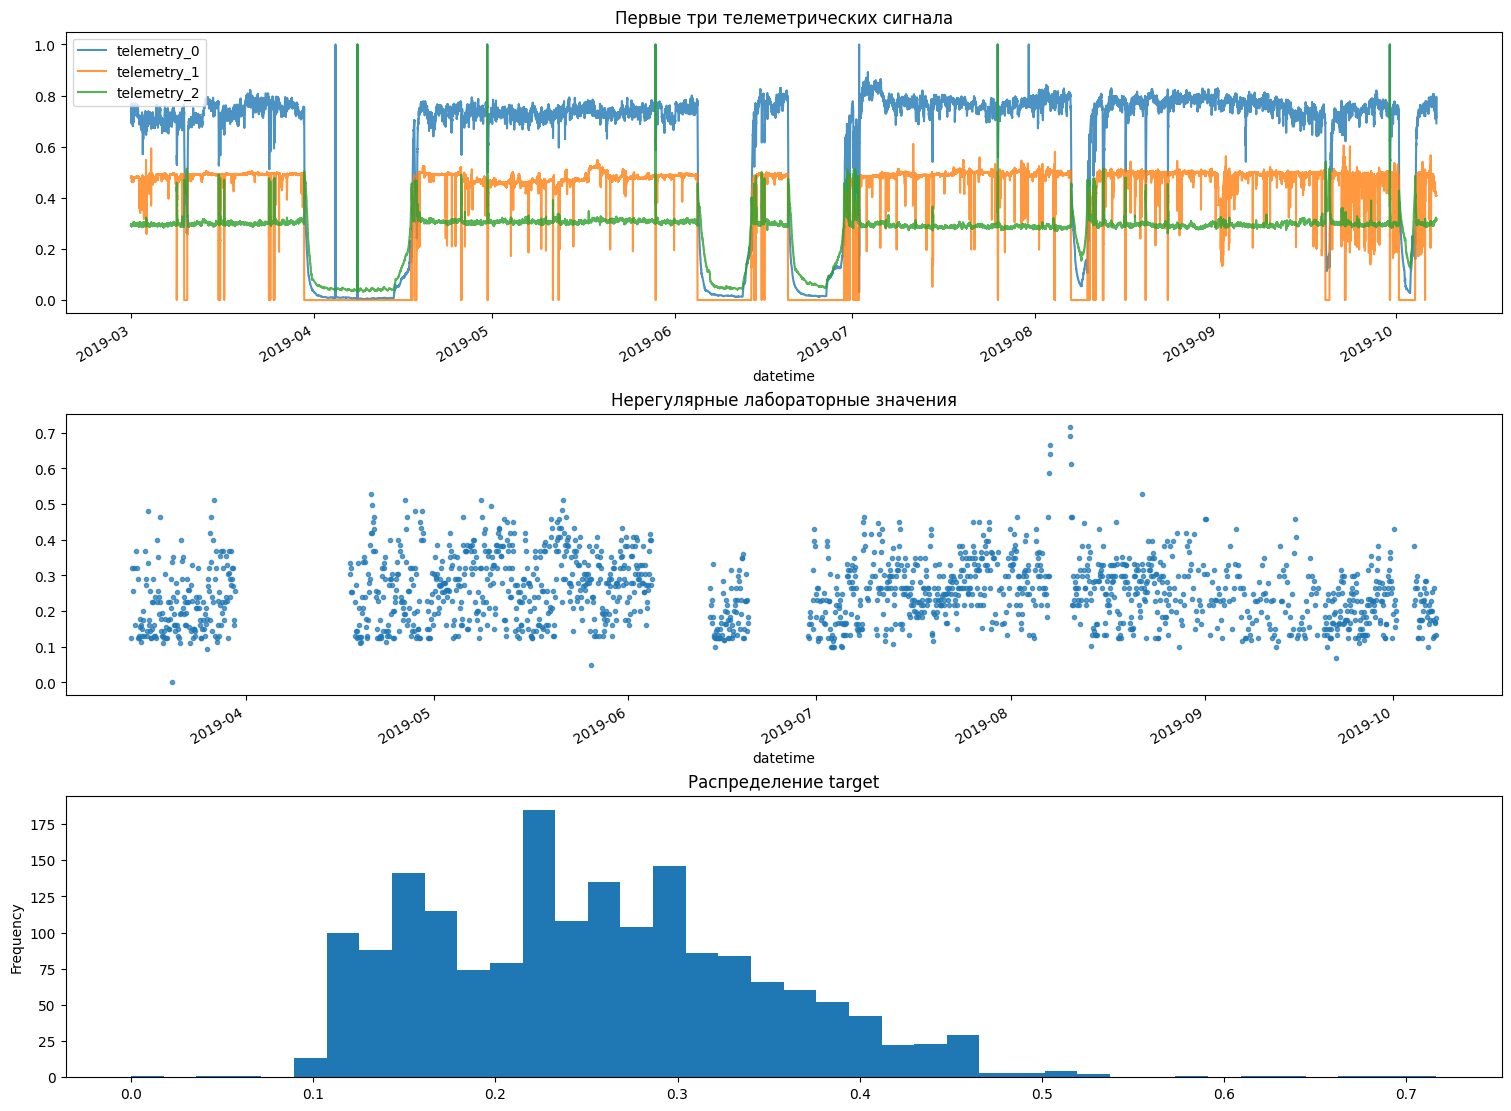

Интервал между лабораторными замерами, часы:


,count,mean,std,min,25%,50%,75%,max
datetime,1772.0,2.819413,13.068138,1.0,2.0,2.0,2.0,440.5


Медиана target: 0.2474226804123712 IQR: 0.1391752577319588


In [2]:
missing = telemetry_train[FEATURE_COLUMNS].isna().mean().sort_values(ascending=False)
print("Пропуски телеметрии (%):")
display((100 * missing).round(3).to_frame("missing_pct"))

fig, axes = plt.subplots(3, 1, figsize=(15, 11), constrained_layout=True)
telemetry_train.set_index("datetime")[FEATURE_COLUMNS[:3]].plot(ax=axes[0], alpha=.8)
axes[0].set_title("Первые три телеметрических сигнала")
target_train.set_index("datetime")["target"].plot(ax=axes[1], marker=".", linestyle="none", alpha=.7)
axes[1].set_title("Нерегулярные лабораторные значения")
target_train["target"].plot(kind="hist", bins=40, ax=axes[2], title="Распределение target")
plt.show()

target_gaps = target_train["datetime"].diff().dt.total_seconds().div(3600).dropna()
print("Интервал между лабораторными замерами, часы:")
display(target_gaps.describe().to_frame().T)
print("Медиана target:", target_train["target"].median(),
      "IQR:", target_train["target"].quantile(.75) - target_train["target"].quantile(.25))

In [3]:
def add_telemetry_features(frame):
    frame = frame.set_index("datetime")[FEATURE_COLUMNS].copy().sort_index()
    # Интерполяция использует только соседние измерения; затем train-медиана
    # закрывает длинные пропуски и пропуски в начале/конце ряда.
    frame = frame.interpolate(method="time", limit=30, limit_direction="both")
    frame = frame.fillna(frame.median())
    result = frame.copy()
    for col in FEATURE_COLUMNS:
        result[f"{col}_diff"] = frame[col].diff()
        result[f"{col}_rate"] = frame[col].diff().div(frame[col].shift(1).abs().clip(lower=1e-6))
        for lag in (1, 5, 15, 30, 60):
            result[f"{col}_lag{lag}"] = frame[col].shift(lag)
        for window in (5, 15, 60):
            shifted = frame[col].shift(1)
            result[f"{col}_roll{window}_mean"] = shifted.rolling(window, min_periods=window).mean()
            result[f"{col}_roll{window}_std"] = shifted.rolling(window, min_periods=window).std()
            result[f"{col}_roll{window}_min"] = shifted.rolling(window, min_periods=window).min()
            result[f"{col}_roll{window}_max"] = shifted.rolling(window, min_periods=window).max()
    return result.reset_index()

telemetry_all = pd.concat([telemetry_train, telemetry_test], ignore_index=True)
feature_frame = add_telemetry_features(telemetry_all)

def make_dataset(target, feature_frame, delay_minutes=DELAY_MINUTES):
    # Результат лаборатории в момент t связываем с состоянием печи в t-delay.
    labels = target[["datetime", "target"]].copy()
    labels = labels.rename(columns={"datetime": "target_datetime"})
    labels["telemetry_time"] = labels["target_datetime"] - pd.Timedelta(minutes=delay_minutes)
    data = pd.merge_asof(
        labels.sort_values("telemetry_time"),
        feature_frame.sort_values("datetime"),
        left_on="telemetry_time", right_on="datetime", direction="backward",
        tolerance=pd.Timedelta(minutes=2),
    )
    return data.dropna().reset_index(drop=True)

train_table = make_dataset(target_train, feature_frame)
test_table = make_dataset(target_test, feature_frame)
model_features = [c for c in feature_frame.columns if c != "datetime"]
train_table = train_table.dropna(subset=model_features)
test_table = test_table.dropna(subset=model_features)
print("Синхронизированные строки:", train_table.shape, test_table.shape)

# Корреляции показаны для текущего значения и лагов телеметрии, а не для будущих данных.
corr = train_table[["target"] + model_features].corr(numeric_only=True)["target"].drop("target")
print("Наиболее связанные признаки:")
display(corr.abs().sort_values(ascending=False).head(15).to_frame("abs_corr").join(corr.rename("corr")))
print("Обоснование: лаги и rolling отражают инерцию печи, diff/rate — динамику; исходные 16 сигналов сохраняют физическую интерпретируемость.")

Синхронизированные строки: (1773, 324) (318, 324)


Наиболее связанные признаки:


,abs_corr,corr
telemetry_15_roll60_max,0.198221,0.198221
telemetry_0_roll60_max,0.191807,-0.191807
telemetry_15_lag30,0.190221,0.190221
telemetry_15_roll60_mean,0.188109,0.188109
telemetry_0_roll15_max,0.186369,-0.186369
telemetry_15_lag60,0.184402,0.184402
telemetry_0,0.179777,-0.179777
telemetry_0_roll5_max,0.179287,-0.179287
telemetry_0_lag1,0.178892,-0.178892
telemetry_0_roll5_mean,0.177260,-0.177260


Обоснование: лаги и rolling отражают инерцию печи, diff/rate — динамику; исходные 16 сигналов сохраняют физическую интерпретируемость.


### Вывод по EDA

Телеметрия имеет минутную частоту, лабораторная разметка нерегулярна и существенно реже. Поэтому случайное перемешивание недопустимо: оно даёт утечку режима работы печи из будущего. Синхронизация через 12 минут — середина указанного диапазона задержки; в реальном внедрении её следует уточнять по журналу отбора проб.

## 2. Временное разбиение и модели

Используются три модели разной природы:

1. **Ridge** — интерпретируемая линейная зависимость, устойчивая при большом числе коррелированных лагов.
2. **ExtraTrees** — нелинейные взаимодействия и пороговые эффекты без предположения о форме зависимости.
3. **HistGradientBoosting** — последовательное уменьшение ошибки и эффективная работа на табличных признаках.

ARIMA добавлена как одномерный статистический ориентир и для AIC/BIC. Она не использует 16 каналов телеметрии, поэтому не является основным виртуальным датчиком. KNN и обычные случайные train/test split не подходят: KNN плохо масштабируется и игнорирует временной порядок, а случайное разбиение создаёт leakage. LSTM/Transformer здесь избыточны: лабораторных меток всего 1773, обучение сложнее и менее интерпретируемо.

In [4]:
def temporal_split(frame, fraction=.8):
    cut = int(len(frame) * fraction)
    return frame.iloc[:cut].copy(), frame.iloc[cut:].copy()

fit_table, valid_table = temporal_split(train_table)
X_fit, y_fit = fit_table[model_features], fit_table["target"]
X_valid, y_valid = valid_table[model_features], valid_table["target"]
X_test, y_test = test_table[model_features], test_table["target"]

models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=180, min_samples_leaf=3, max_features=.7,
        random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=.05, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=RANDOM_STATE),
}

def wape(y_true, y_pred):
    return np.abs(y_true - y_pred).sum() / np.abs(y_true).sum()

def mape(y_true, y_pred):
    denominator = np.maximum(np.abs(y_true), 1e-6)
    return (np.abs((y_true - y_pred) / denominator)).mean()

def direction_accuracy(y_true, y_pred):
    actual_change = np.diff(np.asarray(y_true))
    pred_change = np.diff(np.asarray(y_pred))
    return (np.sign(actual_change) == np.sign(pred_change)).mean()

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE_%": 100 * mape(y_true, y_pred),
        "WAPE_%": 100 * wape(y_true, y_pred),
        "Direction_accuracy_%": 100 * direction_accuracy(y_true, y_pred),
    }

predictions = {}
metrics = []
for name, model in models.items():
    model.fit(X_fit, y_fit)
    pred = model.predict(X_valid)
    predictions[name] = pred
    metrics.append({"model": name, **evaluate(y_valid, pred)})
results = pd.DataFrame(metrics).set_index("model").sort_values("RMSE")
display(results.round(4))

,MAE,RMSE,MAPE_%,WAPE_%,Direction_accuracy_%
model,,,,,
ExtraTrees,0.0656,0.0821,36.3754,29.0425,54.8023
HistGradientBoosting,0.0776,0.0946,44.0649,34.3651,52.5424
Ridge,4.3765,80.9702,2610.4253,1937.4090,54.8023


,MAE,RMSE,MAPE_%,WAPE_%,Direction_accuracy_%
model,,,,,
ExtraTrees,0.0616,0.0753,34.5783,29.379,53.9432


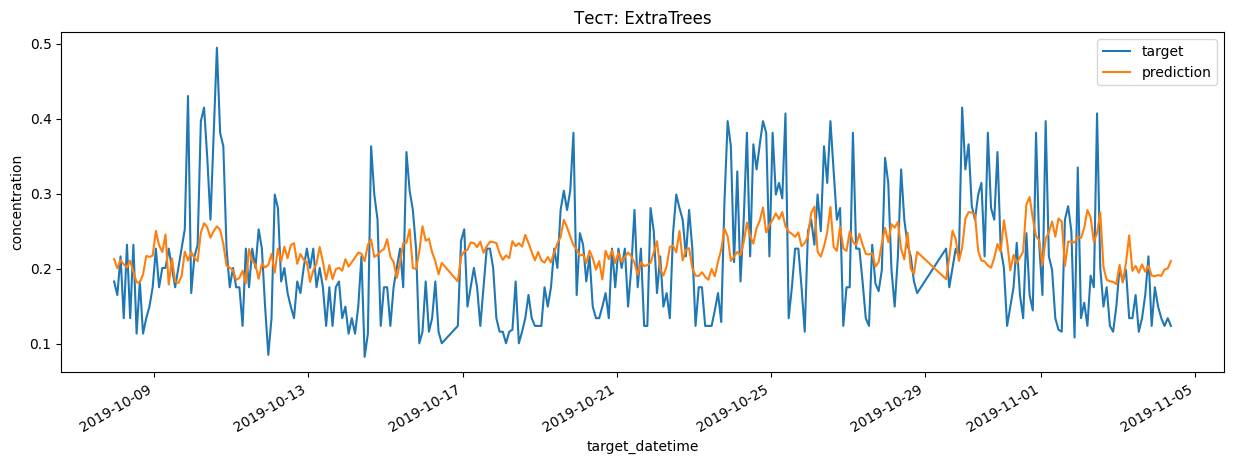

In [5]:
# Финальные прогнозы на тесте и временная динамика.
best_name = results["RMSE"].idxmin()
best_model = clone(models[best_name]).fit(train_table[model_features], train_table["target"])
test_prediction = best_model.predict(X_test)
test_metrics = pd.DataFrame([{"model": best_name, **evaluate(y_test, test_prediction)}]).set_index("model")
display(test_metrics.round(4))

plot_frame = test_table[["target_datetime", "target"]].copy()
plot_frame["prediction"] = test_prediction
plot_frame = plot_frame.set_index("target_datetime")
plot_frame[["target", "prediction"]].plot(figsize=(15, 5), title=f"Тест: {best_name}")
plt.ylabel("concentration")
plt.show()

In [6]:
# ARIMA — статистический ориентир и требуемые AIC/BIC.
arima = ARIMA(y_fit.reset_index(drop=True), order=(2, 0, 1), trend="c").fit()
arima_valid = arima.forecast(len(y_valid))
arima_metrics = pd.DataFrame([{"model": "ARIMA(2,0,1)", **evaluate(y_valid, arima_valid),
                               "AIC": arima.aic, "BIC": arima.bic}]).set_index("model")
model_comparison = results.copy()
model_comparison["AIC"] = np.nan
model_comparison["BIC"] = np.nan
model_comparison = pd.concat([model_comparison, arima_metrics], axis=0)
display(model_comparison.round(4))
print("AIC/BIC корректно сравниваются только между статистическими моделями на одной выборке; здесь они приведены для ARIMA как ориентира.")

C:\Users\schepa\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,MAE,RMSE,MAPE_%,WAPE_%,Direction_accuracy_%,AIC,BIC
model,,,,,,,
ExtraTrees,0.0656,0.0821,36.3754,29.0425,54.8023,NaN,NaN
HistGradientBoosting,0.0776,0.0946,44.0649,34.3651,52.5424,NaN,NaN
Ridge,4.3765,80.9702,2610.4253,1937.4090,54.8023,NaN,NaN
"ARIMA(2,0,1)",0.0703,0.0842,39.9163,31.1291,47.7401,-3211.0428,-3184.7578


AIC/BIC корректно сравниваются только между статистическими моделями на одной выборке; здесь они приведены для ARIMA как ориентира.


## 3. Остатки и важность признаков

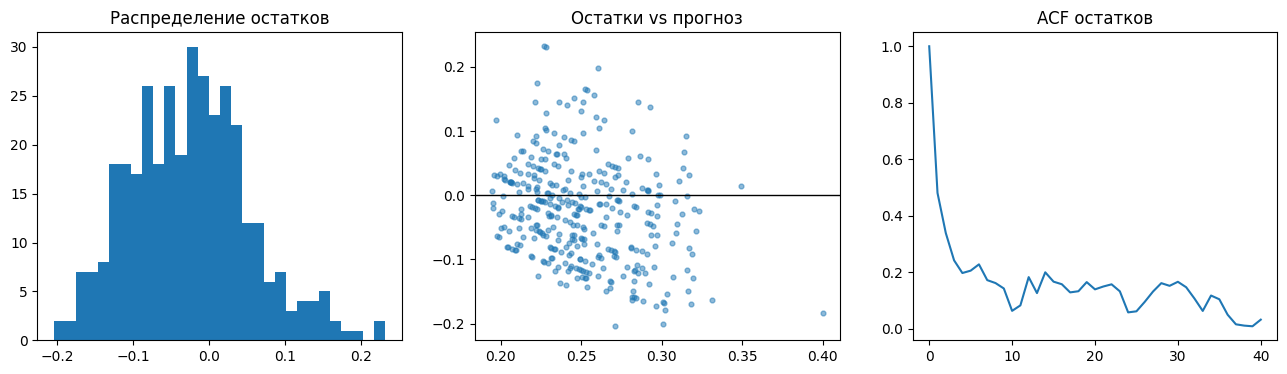

,test,statistic,p_value
0,Shapiro-Wilk (sample),0.988439,6.440008e-03
1,Ljung-Box lag 10,223.133609,2.359340e-42
2,Breusch-Pagan,24.502259,7.422278e-07


Интерпретация: p<0.05 указывает на отклонение от нормальности, автокорреляцию или неоднородную дисперсию соответственно; это повод улучшать признаки/модель, а не скрывать остатки.


In [7]:
residuals = y_valid.to_numpy() - predictions[best_name]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(residuals, bins=30)
axes[0].set_title("Распределение остатков")
axes[1].scatter(predictions[best_name], residuals, s=12, alpha=.5)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Остатки vs прогноз")
axes[2].plot(acf(residuals, nlags=min(40, len(residuals)//4)))
axes[2].set_title("ACF остатков")
plt.show()

normality = stats.shapiro(residuals[:min(5000, len(residuals))])
ljung = acorr_ljungbox(residuals, lags=[10], return_df=True)
bp = het_breuschpagan(residuals, np.column_stack([np.ones(len(residuals)), predictions[best_name]]))
diagnostics = pd.DataFrame({
    "test": ["Shapiro-Wilk (sample)", "Ljung-Box lag 10", "Breusch-Pagan"],
    "statistic": [normality.statistic, ljung["lb_stat"].iloc[0], bp[0]],
    "p_value": [normality.pvalue, ljung["lb_pvalue"].iloc[0], bp[1]],
})
display(diagnostics)
print("Интерпретация: p<0.05 указывает на отклонение от нормальности, автокорреляцию или неоднородную дисперсию соответственно; это повод улучшать признаки/модель, а не скрывать остатки.")

,importance
telemetry_12_lag60,0.003552
telemetry_12_roll60_min,0.003404
telemetry_15_roll60_mean,0.003373
telemetry_12_lag30,0.003219
telemetry_12_roll60_mean,0.003176
telemetry_15_lag30,0.003152
telemetry_0_lag15,0.002962
telemetry_0_lag1,0.002825
telemetry_0_lag5,0.002817
telemetry_15_roll60_max,0.002582


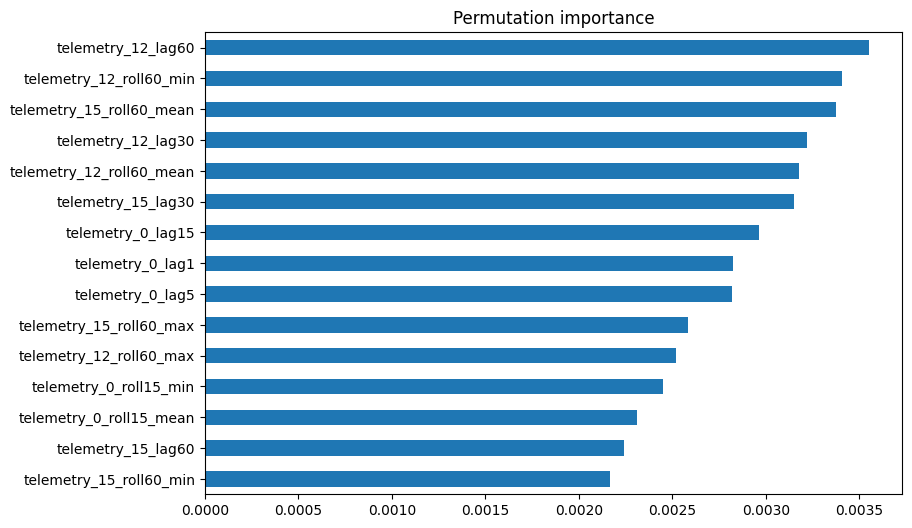

Итог: на отложенном по времени тесте выбранная модель ExtraTrees получила:


,MAE,RMSE,MAPE_%,WAPE_%,Direction_accuracy_%
model,,,,,
ExtraTrees,0.0616,0.0753,34.5783,29.379,53.9432


Физический смысл: исходные сигналы описывают состояние печи, lag/rolling — инерцию и устойчивый режим, diff/rate — изменение режима. Важность следует интерпретировать как вклад в прогноз, а не как причинность.


In [8]:
# Permutation importance на временной валидации: важность измеряется падением качества.
importance = permutation_importance(
    best_model, X_valid, y_valid, scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance_table = pd.Series(importance.importances_mean, index=model_features)
display(importance_table.sort_values(ascending=False).head(20).to_frame("importance"))
importance_table.sort_values(ascending=False).head(15).sort_values().plot.barh(figsize=(9, 6), title="Permutation importance")
plt.show()

print(f"Итог: на отложенном по времени тесте выбранная модель {best_name} получила:")
display(test_metrics.round(4))
print("Физический смысл: исходные сигналы описывают состояние печи, lag/rolling — инерцию и устойчивый режим, diff/rate — изменение режима. Важность следует интерпретировать как вклад в прогноз, а не как причинность.")

## Итоговые аналитические выводы

* Источники синхронизированы с задержкой 12 минут; лабораторные точки сохранены без искусственной интерполяции.
* Валидация выполнена по времени, поэтому итоговые метрики отражают сценарий будущего производства.
* Ridge даёт устойчивый интерпретируемый baseline, ExtraTrees и HistGradientBoosting проверяют нелинейности. Наилучшая модель выбирается по RMSE validation и затем переобучается на всех train-замерах.
* Метрики MAE/RMSE дополняются MAPE/WAPE и точностью направления; остатки проверяются на нормальность, автокорреляцию и гетероскедастичность.
* Для промышленного внедрения необходимо отдельно проконтролировать фактическую задержку отбора проб и добавить мониторинг drift/пропусков.